# Emergency & Incidents Analytics: Python Data Analysis

**Project:** Emergency & Incidents Analytics (graduation project)
**Dataset:** NYC EMS Incident Dispatch Data, NYC Open Data dataset `76xm-jjuj`
**Extract used:** incidents from 2023-10-01 up to (not including) 2026-10-01, downloaded through the NYC Open Data export endpoint and stored as a Parquet file (`nyc_ems_2023_2026.parquet`).
**Scope of this notebook:** data validation, cleaning, feature engineering, exploratory analysis, KPIs, insights, and exports for the SQL / Power BI / Tableau teammates.

## Contents

1. Setup and dataset provenance
2. Initial exploratory analysis and data quality assessment (before cleaning)
3. Data cleaning and data type conversion
4. Feature engineering
5. Post-cleaning exploratory analysis
6. Business analysis
7. Visualizations and business insights
8. Final findings, limitations, and recommendations
9. Exported outputs for the team

The source Parquet file is never modified. Cleaned data is written to a separate `outputs` folder.

## 1. Setup and dataset provenance

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import requests

PROJECT_DIR = Path(r"D:\Graduation_Project")
PARQUET_PATH = PROJECT_DIR / "nyc_ems_2023_2026.parquet"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATETIME_FORMAT = "%m/%d/%Y %I:%M:%S %p"


def text_to_seconds(series):
    """Convert text such as '27,606' to a numeric value."""
    return pd.to_numeric(series.str.replace(",", "", regex=False), errors="coerce")


def seconds_between(start, end):
    return (end - start).dt.total_seconds()

### 1.1 Row count check against the source API (optional)

The Parquet file holds 4,862,291 rows. In the initial run, the API returned the same count (`4862291`) for the same date filter. The request is skipped during routine runs; set `RUN_API_CHECK = True` to repeat it. The API token is read from the `NYC_APP_TOKEN` environment variable and is never stored in the notebook.

In [2]:
RUN_API_CHECK = False

if RUN_API_CHECK:
    token = os.environ.get("NYC_APP_TOKEN")
    headers = {"X-App-Token": token} if token else {}
    params = {
        "$select": "count(*)",
        "$where": (
            "incident_datetime >= '2023-10-01T00:00:00' "
            "AND incident_datetime < '2026-10-01T00:00:00'"
        ),
    }
    response = requests.get(
        "https://data.cityofnewyork.us/resource/76xm-jjuj.json",
        params=params, headers=headers, timeout=60,
    )
    response.raise_for_status()
    api_count = int(response.json()[0]["count"])
    parquet_count = pq.ParquetFile(PARQUET_PATH).metadata.num_rows
    print("API count:", f"{api_count:,}", "| Parquet rows:", f"{parquet_count:,}", "| match:", api_count == parquet_count)
else:
    print("API check skipped (RUN_API_CHECK = False).")

API check skipped (RUN_API_CHECK = False).


## 2. Initial exploratory analysis and data quality assessment

This section examines the raw data before any cleaning decision is made.

### 2.1 Missing values by column

In [3]:
pf = pq.ParquetFile(PARQUET_PATH)
total_rows = pf.metadata.num_rows
print("Rows:", f"{total_rows:,}", "| Columns:", pf.metadata.num_columns)

results = []
for col in pf.schema_arrow.names:
    column = pq.read_table(PARQUET_PATH, columns=[col]).column(0)
    n_null = column.null_count
    results.append({
        "column": col,
        "dtype": str(pf.schema_arrow.field(col).type),
        "missing_count": n_null,
        "missing_pct": round(n_null / total_rows * 100, 2),
    })

missing_df = pd.DataFrame(results).sort_values("missing_pct", ascending=False)
print(missing_df.to_string(index=False))

Rows: 4,862,291 | Columns: 31


                        column        dtype  missing_count  missing_pct
   FIRST_HOSP_ARRIVAL_DATETIME large_string        1942194        39.94
        FIRST_TO_HOSP_DATETIME large_string        1929188        39.68
  INCIDENT_RESPONSE_SECONDS_QY large_string         326101         6.71
 INCIDENT_TRAVEL_TM_SECONDS_QY large_string         324733         6.68
       FIRST_ON_SCENE_DATETIME large_string         324653         6.68
     FIRST_ACTIVATION_DATETIME large_string         136348         2.80
     FIRST_ASSIGNMENT_DATETIME large_string         126103         2.59
       COMMUNITYSCHOOLDISTRICT       double          75557         1.55
           CITYCOUNCILDISTRICT       double          71941         1.48
                POLICEPRECINCT       double          71941         1.48
         CONGRESSIONALDISTRICT       double          71941         1.48
             COMMUNITYDISTRICT       double          71944         1.48
                       ZIPCODE       double          72096      

### 2.2 Sample records

In [4]:
sample_df = next(pf.iter_batches(batch_size=3)).to_pandas()
sample_df.T

,0,1,2
INCIDENT_ID,78327772,78327773,78327775
INCIDENT_DATETIME,10/01/2023 12:00:17 AM,10/01/2023 12:00:56 AM,10/01/2023 12:01:09 AM
INITIAL_CALL_TYPE,STATEP,STNDBY,DRUG
INITIAL_SEVERITY_LEVEL_CODE,2,8,4
FINAL_CALL_TYPE,STATEP,STNDBY,DRUG
FINAL_SEVERITY_LEVEL_CODE,2,8,4
FIRST_ASSIGNMENT_DATETIME,10/01/2023 12:00:37 AM,10/01/2023 07:41:02 AM,10/01/2023 12:02:43 AM
VALID_DISPATCH_RSPNS_TIME_INDC,Y,Y,Y
DISPATCH_RESPONSE_SECONDS_QY,20,"27,606",94
FIRST_ACTIVATION_DATETIME,10/01/2023 12:01:23 AM,10/01/2023 07:41:02 AM,10/01/2023 12:02:54 AM


### 2.3 Date coverage, record uniqueness, and monthly volume

In [5]:
core = pd.read_parquet(PARQUET_PATH, columns=["INCIDENT_ID", "INCIDENT_DATETIME"])
incident_dt = pd.to_datetime(core["INCIDENT_DATETIME"], format=DATETIME_FORMAT, errors="coerce")
incident_month = incident_dt.dt.to_period("M")

print("Rows:", f"{len(core):,}")
print("Unparseable INCIDENT_DATETIME values:", incident_dt.isna().sum())
print("Earliest incident:", incident_dt.min())
print("Latest incident:", incident_dt.max())
print("Duplicate INCIDENT_ID values:", core["INCIDENT_ID"].duplicated().sum())

monthly_counts = incident_month.value_counts().sort_index()
print("Months covered:", len(monthly_counts),
      "| incidents per month, min / max:", f"{monthly_counts.min():,} / {monthly_counts.max():,}")

del core, incident_dt

Rows: 4,862,291
Unparseable INCIDENT_DATETIME values: 0
Earliest incident: 2023-10-01 00:00:17
Latest incident: 2026-09-30 23:59:50


Duplicate INCIDENT_ID values: 0
Months covered: 36 | incidents per month, min / max: 119,980 / 144,021


### 2.4 Validity flags and response-time fields

The dataset contains two validity flags, `VALID_DISPATCH_RSPNS_TIME_INDC` and `VALID_INCIDENT_RSPNS_TIME_INDC`. Their meaning is investigated empirically by comparing each flag with the timestamps and response-time values it relates to. Response-time columns are stored as text with thousands separators, so a temporary numeric copy is created for diagnostics only. No rows are removed. The distribution of valid response times is analysed separately in section 2.9.

In [6]:
RESPONSE_COLUMNS = [
    "VALID_DISPATCH_RSPNS_TIME_INDC",
    "VALID_INCIDENT_RSPNS_TIME_INDC",
    "DISPATCH_RESPONSE_SECONDS_QY",
    "INCIDENT_RESPONSE_SECONDS_QY",
    "INCIDENT_TRAVEL_TM_SECONDS_QY",
    "FIRST_ASSIGNMENT_DATETIME",
    "FIRST_ON_SCENE_DATETIME",
]
raw = pd.read_parquet(PARQUET_PATH, columns=RESPONSE_COLUMNS)

diag = pd.DataFrame({
    "dispatch_flag": raw["VALID_DISPATCH_RSPNS_TIME_INDC"].astype("category"),
    "incident_flag": raw["VALID_INCIDENT_RSPNS_TIME_INDC"].astype("category"),
    "dispatch_seconds": text_to_seconds(raw["DISPATCH_RESPONSE_SECONDS_QY"]),
    "incident_seconds": text_to_seconds(raw["INCIDENT_RESPONSE_SECONDS_QY"]),
    "travel_seconds": text_to_seconds(raw["INCIDENT_TRAVEL_TM_SECONDS_QY"]),
    "has_assignment": raw["FIRST_ASSIGNMENT_DATETIME"].notna(),
    "has_on_scene": raw["FIRST_ON_SCENE_DATETIME"].notna(),
})

for text_col, num_col in [
    ("DISPATCH_RESPONSE_SECONDS_QY", "dispatch_seconds"),
    ("INCIDENT_RESPONSE_SECONDS_QY", "incident_seconds"),
    ("INCIDENT_TRAVEL_TM_SECONDS_QY", "travel_seconds"),
]:
    failed = (raw[text_col].notna() & diag[num_col].isna()).sum()
    print(f"{text_col}: values that failed numeric conversion = {failed}")

print()
print(diag["dispatch_flag"].value_counts(dropna=False))
print()
print(diag["incident_flag"].value_counts(dropna=False))

del raw

DISPATCH_RESPONSE_SECONDS_QY: values that failed numeric conversion = 0
INCIDENT_RESPONSE_SECONDS_QY: values that failed numeric conversion = 0
INCIDENT_TRAVEL_TM_SECONDS_QY: values that failed numeric conversion = 0

dispatch_flag
Y    4735017
N     127274
Name: count, dtype: int64

incident_flag
Y    4536190
N     326101
Name: count, dtype: int64


In [7]:
print("Dispatch flag vs FIRST_ASSIGNMENT_DATETIME present")
print(pd.crosstab(diag["dispatch_flag"], diag["has_assignment"], margins=True))
print()

print("Incident flag vs FIRST_ON_SCENE_DATETIME present")
print(pd.crosstab(diag["incident_flag"], diag["has_on_scene"], margins=True))
print()

print("Dispatch flag vs incident flag")
print(pd.crosstab(diag["dispatch_flag"], diag["incident_flag"], margins=True))

Dispatch flag vs FIRST_ASSIGNMENT_DATETIME present


has_assignment   False     True      All
dispatch_flag                           
N               126103     1171   127274
Y                    0  4735017  4735017
All             126103  4736188  4862291

Incident flag vs FIRST_ON_SCENE_DATETIME present


has_on_scene    False     True      All
incident_flag                          
N              324653     1448   326101
Y                   0  4536190  4536190
All            324653  4537638  4862291

Dispatch flag vs incident flag


incident_flag       N        Y      All
dispatch_flag                          
N              127267        7   127274
Y              198834  4536183  4735017
All            326101  4536190  4862291


In [8]:
for flag_col, seconds_col in [
    ("dispatch_flag", "dispatch_seconds"),
    ("incident_flag", "incident_seconds"),
    ("incident_flag", "travel_seconds"),
]:
    print(f"{seconds_col} by {flag_col}")
    summary = diag.groupby(flag_col, observed=True)[seconds_col].agg(
        rows="size",
        with_value="count",
        min="min",
        max="max",
        zero_values=lambda s: (s == 0).sum(),
        negative_values=lambda s: (s < 0).sum(),
    )
    print(summary.to_string())
    print()

dispatch_seconds by dispatch_flag


                  rows  with_value  min    max  zero_values  negative_values
dispatch_flag                                                               
N               127274      127274    0      0       127274                0
Y              4735017     4735017    0  32394        43536                0

incident_seconds by incident_flag


                  rows  with_value  min      max  zero_values  negative_values
incident_flag                                                                 
N               326101           0  NaN      NaN            0                0
Y              4536190     4536190  0.0  32396.0        43534                0

travel_seconds by incident_flag


                  rows  with_value  min      max  zero_values  negative_values
incident_flag                                                                 
N               326101        1377  0.0  90337.0          170                0
Y              4536190     4536181  0.0  31650.0        54367                0



### 2.5 Metric definitions and timestamp consistency

This section tests how the response-time fields relate to the timestamps, whether timestamp ordering problems occur in rows flagged as valid, and what the rows with an invalid flag look like.

In [9]:
TIME_COLUMNS = [
    "INCIDENT_DATETIME",
    "FIRST_ASSIGNMENT_DATETIME",
    "FIRST_ACTIVATION_DATETIME",
    "FIRST_ON_SCENE_DATETIME",
    "FIRST_TO_HOSP_DATETIME",
    "FIRST_HOSP_ARRIVAL_DATETIME",
    "INCIDENT_CLOSE_DATETIME",
]
time_text = pd.read_parquet(PARQUET_PATH, columns=TIME_COLUMNS)
ts = {c: pd.to_datetime(time_text[c], format=DATETIME_FORMAT, errors="coerce") for c in TIME_COLUMNS}
parse_failures = {c: int((time_text[c].notna() & ts[c].isna()).sum()) for c in TIME_COLUMNS}
print("Datetime parse failures:", parse_failures)
print()
del time_text

dispatch_ok = diag["dispatch_flag"].eq("Y")
incident_ok = diag["incident_flag"].eq("Y")
both_ok = dispatch_ok & incident_ok

identity_tests = {
    "dispatch = assignment - incident (dispatch flag Y)": (
        diag["dispatch_seconds"],
        seconds_between(ts["INCIDENT_DATETIME"], ts["FIRST_ASSIGNMENT_DATETIME"]),
        dispatch_ok,
    ),
    "incident response = on_scene - incident (incident flag Y)": (
        diag["incident_seconds"],
        seconds_between(ts["INCIDENT_DATETIME"], ts["FIRST_ON_SCENE_DATETIME"]),
        incident_ok,
    ),
    "travel = on_scene - assignment (incident flag Y)": (
        diag["travel_seconds"],
        seconds_between(ts["FIRST_ASSIGNMENT_DATETIME"], ts["FIRST_ON_SCENE_DATETIME"]),
        incident_ok,
    ),
    "incident response = dispatch + travel (both flags Y)": (
        diag["incident_seconds"],
        diag["dispatch_seconds"] + diag["travel_seconds"],
        both_ok,
    ),
}
identity_rows = []
for name, (recorded, calculated, mask) in identity_tests.items():
    mismatches = int((recorded[mask] != calculated[mask]).sum())
    identity_rows.append({"check": name, "rows_checked": int(mask.sum()), "mismatches": mismatches})
print(pd.DataFrame(identity_rows).to_string(index=False))
print()

order_pairs = [
    ("INCIDENT_DATETIME", "FIRST_ASSIGNMENT_DATETIME"),
    ("FIRST_ASSIGNMENT_DATETIME", "FIRST_ACTIVATION_DATETIME"),
    ("FIRST_ACTIVATION_DATETIME", "FIRST_ON_SCENE_DATETIME"),
    ("FIRST_ASSIGNMENT_DATETIME", "FIRST_ON_SCENE_DATETIME"),
    ("INCIDENT_DATETIME", "FIRST_ON_SCENE_DATETIME"),
    ("FIRST_ON_SCENE_DATETIME", "FIRST_TO_HOSP_DATETIME"),
    ("FIRST_TO_HOSP_DATETIME", "FIRST_HOSP_ARRIVAL_DATETIME"),
    ("INCIDENT_DATETIME", "INCIDENT_CLOSE_DATETIME"),
]
order_rows = []
for earlier, later in order_pairs:
    comparable = ts[earlier].notna() & ts[later].notna()
    reversed_order = comparable & (ts[earlier] > ts[later])
    order_rows.append({
        "earlier": earlier,
        "later": later,
        "compared": int(comparable.sum()),
        "violations": int(reversed_order.sum()),
        "violations_when_both_flags_Y": int((reversed_order & both_ok).sum()),
    })
print(pd.DataFrame(order_rows).to_string(index=False))
print()

assignment_after_scene = both_ok & (ts["FIRST_ASSIGNMENT_DATETIME"] > ts["FIRST_ON_SCENE_DATETIME"])
print("Rows with both flags Y where assignment is later than on-scene arrival")
print(pd.DataFrame({
    "incident": ts["INCIDENT_DATETIME"],
    "assignment": ts["FIRST_ASSIGNMENT_DATETIME"],
    "on_scene": ts["FIRST_ON_SCENE_DATETIME"],
    "travel_seconds": diag["travel_seconds"],
})[assignment_after_scene].to_string())

Datetime parse failures: {'INCIDENT_DATETIME': 0, 'FIRST_ASSIGNMENT_DATETIME': 0, 'FIRST_ACTIVATION_DATETIME': 0, 'FIRST_ON_SCENE_DATETIME': 0, 'FIRST_TO_HOSP_DATETIME': 0, 'FIRST_HOSP_ARRIVAL_DATETIME': 0, 'INCIDENT_CLOSE_DATETIME': 0}



                                                    check  rows_checked  mismatches
       dispatch = assignment - incident (dispatch flag Y)       4735017           0
incident response = on_scene - incident (incident flag Y)       4536190           0
         travel = on_scene - assignment (incident flag Y)       4536190           9
     incident response = dispatch + travel (both flags Y)       4536183           8



                  earlier                       later  compared  violations  violations_when_both_flags_Y
        INCIDENT_DATETIME   FIRST_ASSIGNMENT_DATETIME   4736188          24                             0
FIRST_ASSIGNMENT_DATETIME   FIRST_ACTIVATION_DATETIME   4725943          12                            10
FIRST_ACTIVATION_DATETIME     FIRST_ON_SCENE_DATETIME   4533719       16968                         16895
FIRST_ASSIGNMENT_DATETIME     FIRST_ON_SCENE_DATETIME   4537637          79                             8
        INCIDENT_DATETIME     FIRST_ON_SCENE_DATETIME   4537638          89                             0
  FIRST_ON_SCENE_DATETIME      FIRST_TO_HOSP_DATETIME   2874238         907                           907
   FIRST_TO_HOSP_DATETIME FIRST_HOSP_ARRIVAL_DATETIME   2920097           3                             3
        INCIDENT_DATETIME     INCIDENT_CLOSE_DATETIME   4860791          88                            51

Rows with both flags Y where assignment is la

**Notes on consistency.**

- Among rows where both flags are `Y`, 8 rows have `FIRST_ASSIGNMENT_DATETIME` later than `FIRST_ON_SCENE_DATETIME`. Seven of them fall in the early-morning hours of the daylight-saving change (the first Sunday of November), which suggests timestamps are local clock times without a time zone. Their travel value is missing, as is one further valid row, which explains the 9 and 8 mismatches in the identity checks above. Response durations should be taken from the `*_SECONDS_QY` columns rather than recomputed from timestamp differences.
- `FIRST_ACTIVATION_DATETIME` is later than `FIRST_ON_SCENE_DATETIME` in about 16,900 valid rows. It is inconsistent and is not used for any response metric.

In [10]:
assignment_gap = seconds_between(ts["INCIDENT_DATETIME"], ts["FIRST_ASSIGNMENT_DATETIME"])
scene_gap = seconds_between(ts["INCIDENT_DATETIME"], ts["FIRST_ON_SCENE_DATETIME"])

dispatch_invalid_with_time = ~dispatch_ok & ts["FIRST_ASSIGNMENT_DATETIME"].notna()
print("Dispatch flag N with an assignment timestamp present:", int(dispatch_invalid_with_time.sum()))
print("  recorded dispatch seconds (distinct values):", [int(v) for v in sorted(diag.loc[dispatch_invalid_with_time, "dispatch_seconds"].unique())])
print("  rows where the timestamp gap equals the recorded value:",
      int((assignment_gap[dispatch_invalid_with_time] == diag.loc[dispatch_invalid_with_time, "dispatch_seconds"]).sum()))
print("  median incident-to-assignment gap (hours):", round(assignment_gap[dispatch_invalid_with_time].median() / 3600, 1))
print()

travel_on_invalid = ~incident_ok & diag["travel_seconds"].notna()
print("Incident flag N with a travel value present:", int(travel_on_invalid.sum()))
print("  median incident-to-on-scene gap (hours):", round(scene_gap[travel_on_invalid].median() / 3600, 1))
print("  median travel seconds on these rows:", diag.loc[travel_on_invalid, "travel_seconds"].median())
print("  median travel seconds on valid rows:", diag.loc[incident_ok, "travel_seconds"].median())

del ts, assignment_gap, scene_gap

Dispatch flag N with an assignment timestamp present: 1171
  recorded dispatch seconds (distinct values): [0]
  rows where the timestamp gap equals the recorded value: 0
  median incident-to-assignment gap (hours): 12.4

Incident flag N with a travel value present: 1377
  median incident-to-on-scene gap (hours): 11.8
  median travel seconds on these rows: 1061.0
  median travel seconds on valid rows: 493.0


### 2.6 Categorical columns and text hygiene

Categorical columns are loaded once in dictionary-encoded form to keep memory low, and are reused in later sections. Text values are checked for whitespace and case inconsistencies.

In [11]:
CATEGORICAL_TEXT = [
    "INITIAL_CALL_TYPE", "FINAL_CALL_TYPE", "BOROUGH", "INCIDENT_DISPATCH_AREA",
    "INCIDENT_DISPOSITION_CODE", "HELD_INDICATOR", "REOPEN_INDICATOR",
    "SPECIAL_EVENT_INDICATOR", "STANDBY_INDICATOR", "TRANSFER_INDICATOR",
]
SEVERITY_COLUMNS = ["INITIAL_SEVERITY_LEVEL_CODE", "FINAL_SEVERITY_LEVEL_CODE"]

cat_df = pq.read_table(
    PARQUET_PATH,
    columns=CATEGORICAL_TEXT + SEVERITY_COLUMNS,
    read_dictionary=CATEGORICAL_TEXT,
).to_pandas()

hygiene_rows = []
for col in CATEGORICAL_TEXT:
    values = pd.Series(cat_df[col].cat.categories)
    normalized = values.str.strip().str.upper()
    hygiene_rows.append({
        "column": col,
        "unique_values": len(values),
        "unique_after_strip_and_upper": normalized.nunique(),
        "values_with_edge_whitespace": int((values != values.str.strip()).sum()),
        "empty_values": int((normalized == "").sum()),
    })
print(pd.DataFrame(hygiene_rows).to_string(index=False))
print()

for col in SEVERITY_COLUMNS:
    print(cat_df[col].value_counts(dropna=False).sort_index().to_string())
    print()

for col in ["BOROUGH", "HELD_INDICATOR", "REOPEN_INDICATOR", "SPECIAL_EVENT_INDICATOR",
            "STANDBY_INDICATOR", "TRANSFER_INDICATOR"]:
    print(cat_df[col].value_counts(dropna=False).to_string())
    print()

for col in ["INITIAL_CALL_TYPE", "FINAL_CALL_TYPE", "INCIDENT_DISPOSITION_CODE"]:
    print(f"Top values: {col}")
    print(cat_df[col].value_counts().head(10).to_string())
    print()

                   column  unique_values  unique_after_strip_and_upper  values_with_edge_whitespace  empty_values
        INITIAL_CALL_TYPE            136                           136                            0             0
          FINAL_CALL_TYPE            152                           152                            0             0
                  BOROUGH              6                             6                            0             0
   INCIDENT_DISPATCH_AREA             34                            34                            0             0
INCIDENT_DISPOSITION_CODE             15                            15                            0             0
           HELD_INDICATOR              2                             2                            0             0
         REOPEN_INDICATOR              2                             2                            0             0
  SPECIAL_EVENT_INDICATOR              2                             2                  

STANDBY_INDICATOR
N    4850605
Y      11686

TRANSFER_INDICATOR
N    4862283
Y          8

Top values: INITIAL_CALL_TYPE
INITIAL_CALL_TYPE
INJURY    592624
SICK      531724
UNKNOW    478224
CARDBR    320947
UNC       308067
CARD      255014
DRUG      252195
EDP       216710
ABDPN     206808
DIFFBR    201634

Top values: FINAL_CALL_TYPE
FINAL_CALL_TYPE
SICK      592694
INJURY    562907
UNKNOW    396830
CARDBR    326774
DRUG      294100
UNC       288503
CARD      266627
EDPC      229650
ABDPN     208291
DIFFBR    199404

Top values: INCIDENT_DISPOSITION_CODE
INCIDENT_DISPOSITION_CODE
82        2935232
93         847460
90         427117
96         200334
CANCEL     142219
91         135262
87         126591
83          37150
94           7668
NOTSNT       1421



### 2.7 Zero-second responses

A zero response time is physically unlikely for a real response. This section checks how common zeros are among valid records and what else is true of them.

In [12]:
valid_incident = diag["incident_flag"].eq("Y")
zero_mask = valid_incident & diag["incident_seconds"].eq(0)

print("Valid incident responses:", f"{valid_incident.sum():,}")
print("Of which zero seconds:", f"{zero_mask.sum():,}", f"({zero_mask.sum() / valid_incident.sum():.2%})")
print("Zero incident response with dispatch = 0 and travel = 0:",
      f"{(zero_mask & diag['dispatch_seconds'].eq(0) & diag['travel_seconds'].eq(0)).sum():,}")
print()

for col in ["STANDBY_INDICATOR", "HELD_INDICATOR", "REOPEN_INDICATOR"]:
    comparison = pd.DataFrame({
        "share_among_zero": cat_df.loc[zero_mask, col].value_counts(normalize=True),
        "share_among_all_valid": cat_df.loc[valid_incident, col].value_counts(normalize=True),
    }).round(3)
    print(col)
    print(comparison)
    print()

print("Top initial call types among zero-second responses")
print(cat_df.loc[zero_mask, "INITIAL_CALL_TYPE"].value_counts().head(5))

Valid incident responses: 4,536,190
Of which zero seconds: 43,534 (0.96%)
Zero incident response with dispatch = 0 and travel = 0: 43,534



STANDBY_INDICATOR
                   share_among_zero  share_among_all_valid
STANDBY_INDICATOR                                         
N                             0.945                  0.998
Y                             0.055                  0.002

HELD_INDICATOR
                share_among_zero  share_among_all_valid
HELD_INDICATOR                                         
N                          0.967                  0.796
Y                          0.033                  0.204



REOPEN_INDICATOR
                  share_among_zero  share_among_all_valid
REOPEN_INDICATOR                                         
N                            0.996                  0.984
Y                            0.004                  0.016

Top initial call types among zero-second responses
INITIAL_CALL_TYPE
SICK      7800
DRUG      6617
INJURY    6515
UNKNOW    4354
MVAINJ    3111
Name: count, dtype: int64


### 2.8 Business-key duplicates

`INCIDENT_ID` is unique, but the same event could still be stored under two IDs. Rows are compared on a business key made of timestamps, call type, dispatch area, and ZIP code. Each column is converted to integer codes as it is read to limit memory use.

In [13]:
KEY_COLUMNS = [
    "INCIDENT_DATETIME", "INITIAL_CALL_TYPE", "INCIDENT_DISPATCH_AREA", "ZIPCODE",
    "FIRST_ASSIGNMENT_DATETIME", "FIRST_ON_SCENE_DATETIME", "INCIDENT_CLOSE_DATETIME",
]
key_codes = pd.DataFrame({
    col: pd.factorize(pd.read_parquet(PARQUET_PATH, columns=[col])[col])[0].astype("int32")
    for col in KEY_COLUMNS
})
print("Rows sharing an identical business key with another row:", f"{int(key_codes.duplicated(keep=False).sum()):,}")
del key_codes

Rows sharing an identical business key with another row: 0


### 2.9 Distribution of valid response times

Only records where the relevant validity flag is `Y` are used. The mean is compared with percentiles because long tails can make the mean misleading.

Seconds (valid records only)
       dispatch   travel  incident_response
P1          3.0      0.0                1.0
P5          6.0    166.0              203.0
P25        14.0    332.0              381.0
P50        31.0    493.0              574.0
P75        98.0    741.0              947.0
P90       687.0   1135.0             1880.0
P95      1913.0   1537.0             3168.0
P99      6620.0   3288.0             8192.0
P99.9   18277.0   9118.0            19939.0
mean      369.0    649.0             1000.0
max     32394.0  31650.0            32396.0

Share of valid records above duration thresholds
                   over_1h_pct  over_3h_pct  over_6h_pct
dispatch                 2.487        0.383        0.056
travel                   0.833        0.064        0.004
incident_response        4.159        0.546        0.075


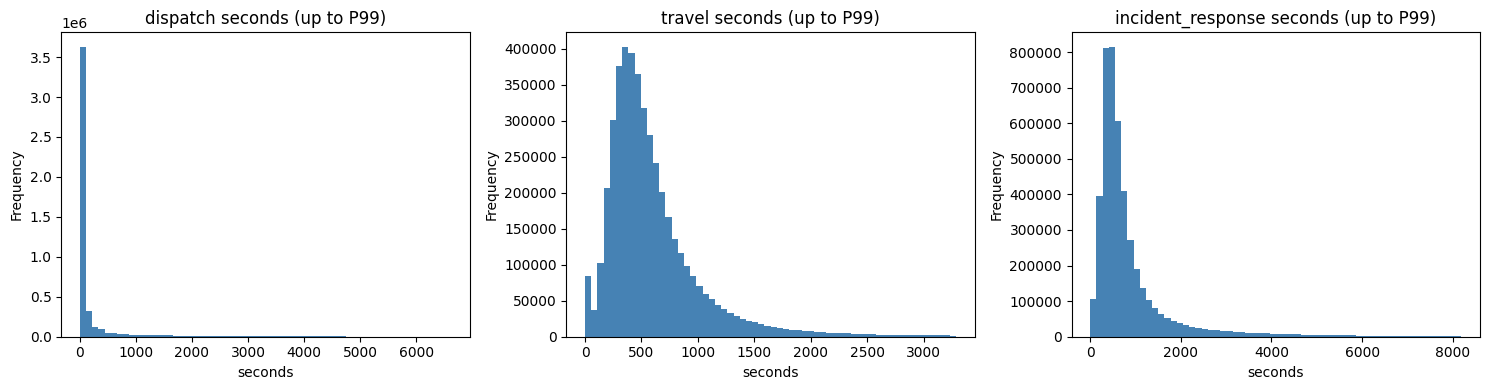

In [14]:
valid_series = {
    "dispatch": diag.loc[diag["dispatch_flag"].eq("Y"), "dispatch_seconds"],
    "travel": diag.loc[diag["incident_flag"].eq("Y"), "travel_seconds"],
    "incident_response": diag.loc[diag["incident_flag"].eq("Y"), "incident_seconds"],
}
quantiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]

distribution = pd.DataFrame({name: s.quantile(quantiles) for name, s in valid_series.items()})
distribution.index = [f"P{q * 100:g}" for q in quantiles]
distribution.loc["mean"] = [s.mean() for s in valid_series.values()]
distribution.loc["max"] = [s.max() for s in valid_series.values()]
print("Seconds (valid records only)")
print(distribution.round(0).to_string())
print()

long_waits = pd.DataFrame({
    f"over_{hours}h_pct": [(s > hours * 3600).mean() * 100 for s in valid_series.values()]
    for hours in (1, 3, 6)
}, index=valid_series.keys()).round(3)
print("Share of valid records above duration thresholds")
print(long_waits)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, s) in zip(axes, valid_series.items()):
    s[s <= s.quantile(0.99)].plot.hist(bins=60, ax=ax, color="steelblue")
    ax.set_title(f"{name} seconds (up to P99)")
    ax.set_xlabel("seconds")
plt.tight_layout()
plt.show()

### 2.10 Stability of flags and zero responses over time

If the invalid-flag rate or the zero-response rate changes sharply between months, the cause may be a recording or system change rather than real operations.

                   incidents  dispatch_flag_N_pct  incident_flag_N_pct  zero_response_pct_of_valid
INCIDENT_DATETIME                                                                                 
2023-10               141460                 1.47                 5.45                        0.88
2023-11               130693                 1.17                 4.63                        0.80
2023-12               142866                 2.05                 5.69                        0.74
2024-01               137245                 1.14                 4.50                        0.70
2024-02               124474                 0.81                 4.23                        0.68
2024-03               132385                 1.03                 4.59                        0.77
2024-04               129362                 1.35                 4.87                        0.85
2024-05               144021                 2.49                 6.64                        1.00
2024-06   

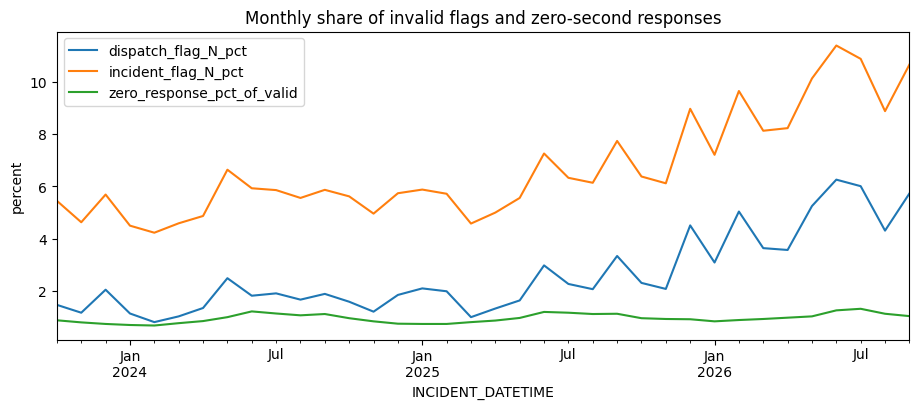

In [15]:
valid_incident_mask = diag["incident_flag"].eq("Y")
zero_valid = valid_incident_mask & diag["incident_seconds"].eq(0)

monthly_quality = pd.DataFrame({
    "incidents": monthly_counts,
    "dispatch_flag_N_pct": diag["dispatch_flag"].eq("N").groupby(incident_month).mean() * 100,
    "incident_flag_N_pct": diag["incident_flag"].eq("N").groupby(incident_month).mean() * 100,
    "zero_response_pct_of_valid": zero_valid.groupby(incident_month).sum() / valid_incident_mask.groupby(incident_month).sum() * 100,
}).round(2)
print(monthly_quality.to_string())

monthly_quality[["dispatch_flag_N_pct", "incident_flag_N_pct", "zero_response_pct_of_valid"]].plot(figsize=(11, 4))
plt.ylabel("percent")
plt.title("Monthly share of invalid flags and zero-second responses")
plt.show()

### 2.11 Hospital fields: missing by design or missing by error?

Hospital timestamps should exist only when a patient was transported. This section checks how the two hospital timestamps relate to each other and to the disposition code.

In [16]:
hosp = pd.read_parquet(
    PARQUET_PATH, columns=["FIRST_TO_HOSP_DATETIME", "FIRST_HOSP_ARRIVAL_DATETIME"]
).notna()
hosp.columns = ["departure_recorded", "arrival_recorded"]
hosp["disposition_code"] = cat_df["INCIDENT_DISPOSITION_CODE"]

print("Hospital departure recorded vs hospital arrival recorded")
print(pd.crosstab(hosp["departure_recorded"], hosp["arrival_recorded"], margins=True))
print()

by_disposition = hosp.groupby("disposition_code", observed=True).agg(
    incidents=("departure_recorded", "size"),
    pct_departure_recorded=("departure_recorded", "mean"),
    pct_arrival_recorded=("arrival_recorded", "mean"),
).sort_values("incidents", ascending=False)
by_disposition[["pct_departure_recorded", "pct_arrival_recorded"]] *= 100
print(by_disposition.round(1).to_string())
del hosp

Hospital departure recorded vs hospital arrival recorded


arrival_recorded      False     True      All
departure_recorded                           
False               1929188        0  1929188
True                  13006  2920097  2933103
All                 1942194  2920097  4862291

                  incidents  pct_departure_recorded  pct_arrival_recorded
disposition_code                                                         
82                  2935232                    99.7                  99.4
93                   847460                     0.8                   0.4
90                   427117                     0.1                   0.0
96                   200334                     0.1                   0.0
CANCEL               142219                     0.0                   0.0
91                   135262                     0.1                   0.0
87                   126591                     0.2                   0.1
83                    37150                     0.1                   0.1
94                     7668  

### 2.12 Geographic missingness pattern

In [17]:
GEO_COLUMNS = [
    "ZIPCODE", "POLICEPRECINCT", "CITYCOUNCILDISTRICT",
    "COMMUNITYDISTRICT", "COMMUNITYSCHOOLDISTRICT", "CONGRESSIONALDISTRICT",
]
geo_missing = pd.read_parquet(PARQUET_PATH, columns=GEO_COLUMNS).isna()

print("Rows missing all six geographic fields:", f"{int(geo_missing.all(axis=1).sum()):,}")
print("Rows missing at least one:", f"{int(geo_missing.any(axis=1).sum()):,}")
print()
print("Number of geographic fields missing per row")
print(geo_missing.sum(axis=1).value_counts().sort_index().to_string())
print()

for group_col, label in [("BOROUGH", "borough"), ("INCIDENT_DISPATCH_AREA", "dispatch area")]:
    rates = geo_missing["ZIPCODE"].groupby(cat_df[group_col], observed=True).agg(["size", "mean"])
    rates["mean"] = (rates["mean"] * 100).round(2)
    rates = rates.rename(columns={"size": "incidents", "mean": "zip_missing_pct"})
    print(f"ZIP code missing rate by {label} (%)")
    print(rates.sort_values("zip_missing_pct", ascending=False).head(8).to_string())
    print()
del geo_missing

Rows missing all six geographic fields: 71,941
Rows missing at least one: 75,649

Number of geographic fields missing per row


0    4786642
1       3642
2         66
6      71941

ZIP code missing rate by borough (%)
                          incidents  zip_missing_pct
BOROUGH                                             
UNKNOWN                          17           100.00
QUEENS                       996530             2.79
RICHMOND / STATEN ISLAND     208098             2.29
BRONX                       1145062             1.27
BROOKLYN                    1341693             1.05
MANHATTAN                   1170891             0.93



ZIP code missing rate by dispatch area (%)
                        incidents  zip_missing_pct
INCIDENT_DISPATCH_AREA                            
X2                             39            58.97
CW                            784            38.90
X1                            176            38.07
Q5                          57602             5.36
Q7                         114164             4.98
Q4                          90243             3.50
S3                          27531             3.37
S2                          78757             2.92



### 2.13 Severity and call-type changes, and a sanity check of severity codes

The severity code ordering is not documented in the data. Comparing response times across codes shows whether the codes behave like a priority scale.

In [18]:
initial_sev = cat_df["INITIAL_SEVERITY_LEVEL_CODE"]
final_sev = cat_df["FINAL_SEVERITY_LEVEL_CODE"]

print("Initial severity (rows) vs final severity (columns), row percentages")
print((pd.crosstab(initial_sev, final_sev, normalize="index") * 100).round(1).to_string())
print()
print("Severity unchanged:", f"{(initial_sev == final_sev).mean():.1%}")
call_categories = cat_df["INITIAL_CALL_TYPE"].cat.categories.union(cat_df["FINAL_CALL_TYPE"].cat.categories)
initial_call = cat_df["INITIAL_CALL_TYPE"].cat.set_categories(call_categories)
final_call = cat_df["FINAL_CALL_TYPE"].cat.set_categories(call_categories)
print("Call type unchanged:", f"{(initial_call == final_call).mean():.1%}")
print()

by_severity = pd.DataFrame({
    "initial_severity": initial_sev,
    "dispatch": diag["dispatch_seconds"].where(diag["dispatch_flag"].eq("Y")),
    "incident": diag["incident_seconds"].where(diag["incident_flag"].eq("Y")),
}).groupby("initial_severity").agg(
    incidents=("dispatch", "size"),
    median_dispatch=("dispatch", "median"),
    p90_dispatch=("dispatch", lambda s: s.quantile(0.9)),
    median_incident=("incident", "median"),
    p90_incident=("incident", lambda s: s.quantile(0.9)),
)
print("Valid response seconds by initial severity code")
print(by_severity.round(0).to_string())

del cat_df, diag, valid_series, incident_month, valid_incident_mask, zero_valid

Initial severity (rows) vs final severity (columns), row percentages


FINAL_SEVERITY_LEVEL_CODE       1     2     3     4     5     6     7     8
INITIAL_SEVERITY_LEVEL_CODE                                                
1                            80.4   5.4   2.7   3.0   4.8   2.8   0.9   0.0
2                             1.8  87.9   1.2   0.8   2.5   5.4   0.5   0.0
3                             0.4   3.3  88.5   0.4   2.3   3.8   1.3   0.0
4                             0.5   5.0   3.8  82.7   3.1   3.3   1.6   0.0
5                             0.1   2.2   5.1   1.0  90.2   0.6   0.9   0.0
6                             0.1   2.7   3.9   1.7   2.9  88.1   0.7   0.0
7                             0.1   1.4   2.1   3.3   4.9   2.0  86.2   0.0
8                             0.1   2.7   0.9   1.4   3.5   1.4   2.3  87.8
9                             4.5  11.4  13.6  18.2  31.8   6.8   6.8   6.8

Severity unchanged: 87.5%
Call type unchanged: 84.9%



Valid response seconds by initial severity code
                  incidents  median_dispatch  p90_dispatch  median_incident  p90_incident
initial_severity                                                                         
1                     71460             23.0          58.0            347.0         592.0
2                   1042683             23.0          84.0            442.0         797.0
3                    702691             25.0          95.0            450.0         820.0
4                    733916             34.0         708.0            656.0        1900.0
5                   1133411             37.0        1481.0            696.0        2608.0
6                    593337             45.0        2233.0            750.0        3450.0
7                    570187             84.0        2116.0            990.0        3582.0
8                     14562             34.0       20876.0            664.0       21686.0
9                        44              0.0        

## 3. Data cleaning and data type conversion

### 3.1 Cleaning decisions

Decisions are based on the checks in section 2. No row is removed in this section; the source Parquet file is left untouched, so all original values remain available for comparison.

| Issue | Action | Reason |
|---|---|---|
| Datetime columns stored as text | Convert to `datetime64` using the explicit source format | Required for time-based analysis; sections 2.3 and 2.5 found no parse failures |
| Response-time columns stored as text with thousands separators | Remove separators and convert to nullable integers | Required for any numeric calculation |
| Dispatch seconds recorded as 0 where the dispatch flag is `N` | Set to missing | Sections 2.4 and 2.5: the value is always 0, almost all of these rows have no assignment timestamp, and for the rest it never equals the timestamp gap. It is a placeholder, not a measurement, and would bias averages downward |
| Travel seconds present where the incident flag is `N` | **Kept as recorded** | No travel-specific validity rule exists. Section 2.5 suggests these values come from questionable on-scene timestamps, but this is an inference, so the decision is deferred (see 3.5) |
| Valid responses with 0 seconds | Keep, add `is_zero_response` (missing when the response is missing) | Cannot be confirmed as errors; the decision to exclude them is left to each KPI |
| Y/N flag columns stored as text | Convert to nullable boolean; unexpected values stop the conversion | Missing or unknown values are never silently turned into `False` |
| Call type, borough, dispatch area, disposition code | Load as `category`; values kept as the source codes | Lower memory use |
| Geographic columns stored as floating point | Convert to nullable integers; ZIP code as text | They are identifiers, not measurements |
| Hospital timestamps and geographic fields missing | Keep as missing | Section 2.11: hospital fields are filled almost only for disposition `82`; geographic missingness is small and cannot be imputed |
| Timestamp order violations | Keep and document | Counts are small for the fields used in response metrics and mostly fall in flagged rows; a few fall on daylight-saving changes. `FIRST_ACTIVATION_DATETIME` is inconsistent and is not used (section 2.5) |
| Duplicates | None found; no rows removed | `INCIDENT_ID` is unique and no business-key duplicates exist (section 2.8) |
| Column names in legacy upper-case style | Rename to lower snake_case | Consistent naming for the whole team |

### 3.2 Build the cleaned dataset

In [19]:
COLUMN_RENAMES = {
    "INCIDENT_ID": "incident_id",
    "INCIDENT_DATETIME": "incident_datetime",
    "INITIAL_CALL_TYPE": "initial_call_type",
    "INITIAL_SEVERITY_LEVEL_CODE": "initial_severity_level",
    "FINAL_CALL_TYPE": "final_call_type",
    "FINAL_SEVERITY_LEVEL_CODE": "final_severity_level",
    "FIRST_ASSIGNMENT_DATETIME": "first_assignment_datetime",
    "VALID_DISPATCH_RSPNS_TIME_INDC": "is_valid_dispatch_response",
    "DISPATCH_RESPONSE_SECONDS_QY": "dispatch_response_seconds",
    "FIRST_ACTIVATION_DATETIME": "first_activation_datetime",
    "FIRST_ON_SCENE_DATETIME": "first_on_scene_datetime",
    "VALID_INCIDENT_RSPNS_TIME_INDC": "is_valid_incident_response",
    "INCIDENT_RESPONSE_SECONDS_QY": "incident_response_seconds",
    "INCIDENT_TRAVEL_TM_SECONDS_QY": "incident_travel_seconds",
    "FIRST_TO_HOSP_DATETIME": "first_to_hosp_datetime",
    "FIRST_HOSP_ARRIVAL_DATETIME": "first_hosp_arrival_datetime",
    "INCIDENT_CLOSE_DATETIME": "incident_close_datetime",
    "HELD_INDICATOR": "is_held",
    "INCIDENT_DISPOSITION_CODE": "incident_disposition_code",
    "BOROUGH": "borough",
    "INCIDENT_DISPATCH_AREA": "incident_dispatch_area",
    "ZIPCODE": "zipcode",
    "POLICEPRECINCT": "police_precinct",
    "CITYCOUNCILDISTRICT": "city_council_district",
    "COMMUNITYDISTRICT": "community_district",
    "COMMUNITYSCHOOLDISTRICT": "community_school_district",
    "CONGRESSIONALDISTRICT": "congressional_district",
    "REOPEN_INDICATOR": "is_reopened",
    "SPECIAL_EVENT_INDICATOR": "is_special_event",
    "STANDBY_INDICATOR": "is_standby",
    "TRANSFER_INDICATOR": "is_transfer",
}
DATETIME_COLUMNS = [
    "incident_datetime", "first_assignment_datetime", "first_activation_datetime",
    "first_on_scene_datetime", "first_to_hosp_datetime", "first_hosp_arrival_datetime",
    "incident_close_datetime",
]
SECONDS_COLUMNS = ["dispatch_response_seconds", "incident_response_seconds", "incident_travel_seconds"]
BOOLEAN_COLUMNS = [
    "is_valid_dispatch_response", "is_valid_incident_response", "is_held",
    "is_reopened", "is_special_event", "is_standby", "is_transfer",
]
DISTRICT_COLUMNS = [
    "police_precinct", "city_council_district", "community_district",
    "community_school_district", "congressional_district",
]
CATEGORY_SOURCE_COLUMNS = [
    "INITIAL_CALL_TYPE", "FINAL_CALL_TYPE", "BOROUGH",
    "INCIDENT_DISPATCH_AREA", "INCIDENT_DISPOSITION_CODE",
]

# Dictionary-encoded loading makes the five repeated-text columns categorical and saves memory
clean = pq.read_table(PARQUET_PATH, read_dictionary=CATEGORY_SOURCE_COLUMNS).to_pandas()
clean = clean.rename(columns=COLUMN_RENAMES)
rows_before = len(clean)
missing_before = clean.isna().sum()

for col in DATETIME_COLUMNS:
    clean[col] = pd.to_datetime(clean[col], format=DATETIME_FORMAT, errors="coerce")

unexpected_flag_values = {}
for col in BOOLEAN_COLUMNS:
    as_boolean = clean[col].map({"Y": True, "N": False}).astype("boolean")
    unexpected_flag_values[col] = int((clean[col].notna() & as_boolean.isna()).sum())
    clean[col] = as_boolean
if any(unexpected_flag_values.values()):
    raise ValueError(f"Unexpected flag values found: {unexpected_flag_values}")

for col in SECONDS_COLUMNS:
    clean[col] = text_to_seconds(clean[col]).astype("Int32")

dispatch_invalid = clean["is_valid_dispatch_response"].eq(False).fillna(False).astype(bool)
incident_invalid = clean["is_valid_incident_response"].eq(False).fillna(False).astype(bool)

dispatch_placeholders = clean.loc[dispatch_invalid, "dispatch_response_seconds"]
placeholder_distinct_values = [int(v) for v in sorted(dispatch_placeholders.dropna().unique())]
clean.loc[dispatch_invalid, "dispatch_response_seconds"] = pd.NA

travel_on_invalid_rows = int((incident_invalid & clean["incident_travel_seconds"].notna()).sum())

clean["is_zero_response"] = clean["incident_response_seconds"].eq(0)

clean["initial_severity_level"] = clean["initial_severity_level"].astype("Int8")
clean["final_severity_level"] = clean["final_severity_level"].astype("Int8")
clean["zipcode"] = clean["zipcode"].astype("Int32").astype("string")
for col in DISTRICT_COLUMNS:
    clean[col] = clean[col].astype("Int16")

print("Rows:", f"{len(clean):,}", "| Columns:", clean.shape[1])
print("Flag values other than Y/N:", sum(unexpected_flag_values.values()))
print("Dispatch placeholder values set to missing:", f"{len(dispatch_placeholders):,}",
      "| distinct original values:", placeholder_distinct_values)
print("Travel values kept on rows with incident flag N:", f"{travel_on_invalid_rows:,}")
print("Zero-second valid responses flagged:", f"{int(clean['is_zero_response'].sum()):,}")

Rows: 4,862,291 | Columns: 32
Flag values other than Y/N: 0
Dispatch placeholder values set to missing: 127,274 | distinct original values: [0]
Travel values kept on rows with incident flag N: 1,377
Zero-second valid responses flagged: 43,534


### 3.3 Validation of the cleaned dataset

In [20]:
print("Row count before / after:", f"{rows_before:,}", "/", f"{len(clean):,}", "| unchanged:", rows_before == len(clean))
print("incident_id unique:", clean["incident_id"].is_unique)
print("Incident date range:", clean["incident_datetime"].min(), "to", clean["incident_datetime"].max())
print("Memory (GB):", round(clean.memory_usage(deep=True).sum() / 1e9, 2))
print()

missing_after = clean.isna().sum()
missing_change = pd.DataFrame({"before": missing_before, "after": missing_after[missing_before.index]})
missing_change["change"] = missing_change["after"] - missing_change["before"]
print("Columns whose missing count changed:", int((missing_change["change"] != 0).sum()), "of", len(missing_change))
print(missing_change[missing_change["change"] != 0].to_string())
print()

valid_dispatch = clean["is_valid_dispatch_response"].eq(True).fillna(False).astype(bool)
valid_incident = clean["is_valid_incident_response"].eq(True).fillna(False).astype(bool)
dispatch_match = (
    clean.loc[valid_dispatch, "dispatch_response_seconds"].astype("float64")
    == seconds_between(clean["incident_datetime"], clean["first_assignment_datetime"])[valid_dispatch]
).all()
incident_match = (
    clean.loc[valid_incident, "incident_response_seconds"].astype("float64")
    == seconds_between(clean["incident_datetime"], clean["first_on_scene_datetime"])[valid_incident]
).all()
print("Valid dispatch seconds match timestamps:", dispatch_match)
print("Valid incident seconds match timestamps:", incident_match)
print("Negative response values:", int((clean[SECONDS_COLUMNS] < 0).sum().sum()))
print("Incident seconds present where incident flag is N:",
      int((clean["incident_response_seconds"].notna() & incident_invalid).sum()))
print("Flag values unknown (missing):", int(clean[["is_valid_dispatch_response", "is_valid_incident_response"]].isna().sum().sum()))
print()
print(clean.dtypes.to_string())

Row count before / after: 4,862,291 / 4,862,291 | unchanged: True


incident_id unique: True
Incident date range: 2023-10-01 00:00:17 to 2026-09-30 23:59:50
Memory (GB): 0.65



Columns whose missing count changed: 1 of 31
                           before   after  change
dispatch_response_seconds       0  127274  127274



Valid dispatch seconds match timestamps: True
Valid incident seconds match timestamps: True
Negative response values: 0
Incident seconds present where incident flag is N: 0
Flag values unknown (missing): 0

incident_id                             int64
incident_datetime              datetime64[us]
initial_call_type                    category
initial_severity_level                   Int8
final_call_type                      category
final_severity_level                     Int8
first_assignment_datetime      datetime64[us]
is_valid_dispatch_response            boolean
dispatch_response_seconds               Int32
first_activation_datetime      datetime64[us]
first_on_scene_datetime        datetime64[us]
is_valid_incident_response            boolean
incident_response_seconds               Int32
incident_travel_seconds                 Int32
first_to_hosp_datetime         datetime64[us]
first_hosp_arrival_datetime    datetime64[us]
incident_close_datetime        datetime64[us]
is_held    

### 3.4 Save the cleaned dataset and the cleaning log

In [21]:
OUTPUT_DIR.mkdir(exist_ok=True)
CLEAN_PATH = OUTPUT_DIR / "ems_incidents_clean.parquet"
LOG_PATH = OUTPUT_DIR / "cleaning_log.csv"

cleaning_log = pd.DataFrame([
    ("Legacy upper-case column names", "all columns", "Renamed to lower snake_case", 0, "Consistent naming for SQL and BI tools"),
    ("Datetimes stored as text", ", ".join(DATETIME_COLUMNS), "Converted to datetime64", 0, "No parse failures found"),
    ("Response seconds stored as text with commas", ", ".join(SECONDS_COLUMNS), "Converted to nullable Int32", 0, "Numeric calculations require numbers"),
    ("Placeholder zero dispatch seconds where flag is N", "dispatch_response_seconds", "Set to missing (original value was 0)", len(dispatch_placeholders), "Not real measurements; see section 2.5"),
    ("Travel seconds where incident flag is N", "incident_travel_seconds", "Kept as recorded; decision pending", 0, f"{travel_on_invalid_rows} rows affected if excluded; no travel-specific validity rule"),
    ("Zero-second valid responses", "incident_response_seconds", "Kept; flagged in is_zero_response", int(clean["is_zero_response"].sum()), "Exclusion decided per KPI"),
    ("Y/N text flags", ", ".join(BOOLEAN_COLUMNS), "Converted to nullable boolean", 0, "Unknown values stay missing"),
    ("Categorical codes", "call types, borough, dispatch area, disposition code", "Loaded as category", 0, "Lower memory use"),
    ("Geographic identifiers stored as float", "zipcode and district columns", "Converted to nullable integers; ZIP as text", 0, "Identifiers, not measurements"),
    ("Duplicate records", "incident_id", "None found; nothing removed", 0, "incident_id is unique; no business-key duplicates"),
], columns=["issue", "columns", "action", "rows_affected", "reason"])

clean.to_parquet(CLEAN_PATH, index=False)
cleaning_log.to_csv(LOG_PATH, index=False)

saved = pq.ParquetFile(CLEAN_PATH).metadata
print("Saved:", CLEAN_PATH.name, "| rows:", f"{saved.num_rows:,}", "| columns:", saved.num_columns)
print("Saved:", LOG_PATH.name)
print()
print(cleaning_log[["issue", "action", "rows_affected"]].to_string(index=False))

Saved: ems_incidents_clean.parquet | rows: 4,862,291 | columns: 32
Saved: cleaning_log.csv

                                            issue                                      action  rows_affected
                   Legacy upper-case column names                 Renamed to lower snake_case              0
                         Datetimes stored as text                     Converted to datetime64              0
      Response seconds stored as text with commas                 Converted to nullable Int32              0
Placeholder zero dispatch seconds where flag is N       Set to missing (original value was 0)         127274
          Travel seconds where incident flag is N          Kept as recorded; decision pending              0
                      Zero-second valid responses           Kept; flagged in is_zero_response          43534
                                   Y/N text flags               Converted to nullable boolean              0
                                Cate

### 3.5 Open items

- **Travel seconds on rows with an invalid incident flag:** kept as recorded. They should be excluded from travel-time KPIs unless official documentation says otherwise.
- **Zero-second responses:** kept and flagged. Whether to exclude them from response-time KPIs is decided when each KPI is defined.
- **Validity flag definitions:** inferred from the data (section 2.4), not from official documentation.
- **Time zone:** timestamps appear to be local clock times without a time zone, so durations are taken from the recorded seconds columns.
- **Severity code direction:** lower codes behave like higher priority (section 2.13), inferred from response times, not documented.
- **Hospital fields:** 13,006 incidents have a hospital departure time but no arrival time (section 2.11).
- **Rising share of invalid flags over time (section 2.10):** the cause is unknown. Response-time KPIs should always be reported together with the share of incidents that have a valid measurement.